# UMAP de perfiles completos

Basado en `../04.evaluacion/16.Umap_unificado.ipynb`. Se incluyen las imágenes referenciadas por `Identificador` en `data/05.cuadrados/metadata.csv`, excluyendo las carpetas `clase04` (clase 4) y `sin_clase` antes de extraer características. Se utilizan los perfiles completos cuadrados de este directorio, sin agregar los recortes del conjunto unificado ni filtrar por split.

Se conservan los mismos pesos locales de ResNet18 del notebook 17, el preprocesamiento y los parámetros de UMAP para comparar las exploraciones. Cada imagen se representa mediante las 512 características de `avgpool`. UMAP se ajusta sin etiquetas; las clases solo determinan el color. La proyección se ajusta de nuevo sobre los perfiles completos, por lo que sus coordenadas no son directamente comparables con las del notebook 17.

Esta visualización es exploratoria e incluye perfiles usados durante el entrenamiento: no mide generalización ni precisión.

## Configuración

In [1]:
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.datasets.folder import IMG_EXTENSIONS, default_loader
from umap import UMAP

from vasijas.config import load_config
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.evaluacion import validar_identificadores_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from vasijas.umap_evaluacion import (
    ConfiguracionUmap,
    guardar_resultado_umap,
)

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_PATH = (
    PATHS.OUTPUT_MODELS / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
OUTPUT_DIR = PATHS.OUTPUT_UMAP
CSV_PATH = OUTPUT_DIR / f"umap_perfiles_completos_{MODEL_PATH.stem}.csv"
FIGURE_PATH = OUTPUT_DIR / f"umap_perfiles_completos_{MODEL_PATH.stem}.png"
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
UMAP_CONFIG = ConfiguracionUmap(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
DEVICE = seleccionar_dispositivo_procesamiento()

display(
    pd.DataFrame(
        [
            {
                "metadata": str(ruta_relativa(DATA_DIR / "metadata.csv")),
                "modelo": MODEL_PATH.name,
                "dispositivo": str(DEVICE),
                "batch_size": BATCH_SIZE,
                "tamano_imagen": TAMANO_IMAGEN,
                **asdict(UMAP_CONFIG),
            }
        ]
    )
)

,metadata,modelo,dispositivo,batch_size,tamano_imagen,n_neighbors,min_dist,metric,random_state
0,data\05.cuadrados\metadata.csv,model_resnet18_unificado_bs16_lr1e-3_weighted_...,cpu,16,224,15,0.1,cosine,42


## Preparación de los datos

Se busca exactamente un archivo por identificador dentro de `../../data/05.cuadrados`. Los identificadores duplicados, las imágenes faltantes o las rutas ambiguas detienen el proceso; no se descartan registros silenciosamente. Se comprueba además que todos los archivos de imagen del directorio estén referenciados en el CSV.

Después de validar las rutas, se excluyen las imágenes de las carpetas `clase04` y `sin_clase`. Se conserva el orden y todas las columnas del CSV para las filas incluidas, incluidos sus valores faltantes. Se agregan `ruta_relativa` y `clase_carpeta` a partir del archivo encontrado. No se crea un split. El preprocesamiento es el del notebook 17: 224 × 224 y normalización ImageNet, sin aumentación.

In [3]:
CLASES_EXCLUIDAS = {"clase04", "sin_clase"}

metadata_completos = cargar_metadata(DATA_DIR)
validar_identificadores_metadata(metadata_completos)
if metadata_completos.empty:
    raise ValueError("La metadata de perfiles completos está vacía.")

identificadores = metadata_completos["Identificador"].astype(str)
buscados = set(identificadores)
rutas_por_id = {}
rutas_imagenes = [
    ruta
    for ruta in sorted(DATA_DIR.rglob("*"))
    if ruta.is_file() and ruta.suffix.lower() in IMG_EXTENSIONS
]
sin_metadata = [ruta for ruta in rutas_imagenes if ruta.stem not in buscados]
if sin_metadata:
    raise ValueError(
        f"Hay {len(sin_metadata)} imágenes sin metadata: "
        f"{[ruta.relative_to(DATA_DIR).as_posix() for ruta in sin_metadata[:10]]}"
    )
for ruta in rutas_imagenes:
    if ruta.stem in rutas_por_id:
        raise ValueError(f"Hay varias imágenes para {ruta.stem!r}.")
    rutas_por_id[ruta.stem] = ruta

faltantes = buscados - set(rutas_por_id)
if faltantes:
    raise FileNotFoundError(
        f"Faltan {len(faltantes)} imágenes: {sorted(faltantes)[:10]}"
    )

metadata_imagenes = metadata_completos.copy().reset_index(drop=True)
metadata_imagenes["ruta_relativa"] = [
    rutas_por_id[identificador].relative_to(DATA_DIR).as_posix()
    for identificador in identificadores
]
metadata_imagenes["clase_carpeta"] = metadata_imagenes["ruta_relativa"].map(
    lambda ruta: Path(ruta).parts[0]
)
if not metadata_imagenes["ruta_relativa"].is_unique:
    raise ValueError("Las rutas de las imágenes deben ser únicas.")

# Se filtra antes de crear el Dataset y extraer las características.
incluir = ~metadata_imagenes["clase_carpeta"].isin(CLASES_EXCLUIDAS)
print(f"Imágenes excluidas (clase04 y sin_clase): {(~incluir).sum()}")
metadata_imagenes = metadata_imagenes.loc[incluir].reset_index(drop=True)
metadata_completos = metadata_completos.loc[incluir].reset_index(drop=True)
if metadata_imagenes.empty:
    raise ValueError("No quedan imágenes después de excluir clase04 y sin_clase.")

display(metadata_imagenes.groupby("clase_carpeta").size().rename("imagenes").to_frame())
display(metadata_imagenes.head(5))
print(f"Total de imágenes incluidas: {len(metadata_imagenes)}")
print(f"Valores faltantes en Clase Ana: {metadata_imagenes['Clase Ana'].isna().sum()}")

Imágenes excluidas (clase04 y sin_clase): 171


,imagenes
clase_carpeta,
clase01,26
clase02,46
clase03,71
clase05,56
clase06,51
clase07,48
clase08,280
clase09,20
clase10,355


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,ruta_relativa,clase_carpeta
0,al_03a,No,II,1,B,2,2,11.0,182,54,53,ibero,Almedinilla,clase11/al_03a.png,clase11
1,al_03b,No,II,1,B,2,2,11.0,178,57,46,ibero,Almedinilla,clase11/al_03b.png,clase11
2,al_03c,No,II,1,B,2,2,11.0,185,56,49,ibero,Almedinilla,clase11/al_03c.png,clase11
3,al_03d,No,II,1,B,2,2,11.0,160,41,45,ibero,Almedinilla,clase11/al_03d.png,clase11
4,al_03e,No,II,1,B,2,2,11.0,164,54,44,ibero,Almedinilla,clase11/al_03e.png,clase11


Total de imágenes incluidas: 1071
Valores faltantes en Clase Ana: 0


In [4]:
class DatasetPerfilesCompletosConRuta(Dataset):
    """Carga RGB y devuelve la ruta para verificar la identidad de cada vector."""

    def __init__(self, metadata, data_dir, transformacion):
        self.rutas = metadata["ruta_relativa"].tolist()
        self.data_dir = data_dir
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, indice):
        ruta = self.rutas[indice]
        imagen = default_loader(str(self.data_dir / ruta))
        return self.transformacion(imagen), ruta


transformacion_evaluacion = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)[2]
dataset_completos = DatasetPerfilesCompletosConRuta(
    metadata_imagenes, DATA_DIR, transformacion_evaluacion
)
loader_completos = DataLoader(
    dataset_completos,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
print(f"Imágenes: {len(dataset_completos)} · Lotes: {len(loader_completos)}")

Imágenes: 1071 · Lotes: 67


## Extracción de características

Se reconstruye la misma ResNet18 a partir de sus pesos locales, sin descargar pesos. La cantidad de salidas del clasificador se lee del archivo del modelo; no depende de las carpetas de perfiles completos, que también incluyen imágenes sin clase. Se extraen únicamente las características anteriores al clasificador, en modo evaluación y sin gradientes.

Se verifica un vector por imagen, incluido el último lote incompleto. Los vectores quedan en memoria para repetir UMAP con otros parámetros.

In [5]:
state_dict = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
modelo = models.resnet18(weights=None)
modelo.fc = nn.Linear(modelo.fc.in_features, state_dict["fc.weight"].shape[0])
modelo.load_state_dict(state_dict, strict=True)
del state_dict
modelo = modelo.to(DEVICE).eval()
extractor = nn.Sequential(*list(modelo.children())[:-1], nn.Flatten(1)).eval()

bloques = []
rutas_extraidas = []
with torch.inference_mode():
    for numero_lote, (imagenes, rutas) in enumerate(loader_completos, start=1):
        vectores = extractor(imagenes.to(DEVICE))
        bloques.append(vectores.cpu().numpy())
        rutas_extraidas.extend(rutas)
        if numero_lote % 100 == 0 or numero_lote == len(loader_completos):
            print(f"Características: {len(rutas_extraidas)}/{len(dataset_completos)}")

if rutas_extraidas != metadata_imagenes["ruta_relativa"].tolist():
    raise ValueError("Los vectores no corresponden al orden completo de la metadata.")
caracteristicas_completos = np.concatenate(bloques, axis=0)
del bloques
if caracteristicas_completos.shape != (len(metadata_completos), 512):
    raise ValueError("Debe existir un vector de 512 características por imagen.")
if not np.isfinite(caracteristicas_completos).all():
    raise ValueError("Las características contienen valores no finitos.")
metadata_caracteristicas = metadata_imagenes.copy()
print(f"Matriz de características verificada: {caracteristicas_completos.shape}")

Características: 1071/1071
Matriz de características verificada: (1071, 512)


## Proyección y visualización

Se ajusta UMAP sobre todos los vectores de los perfiles completos, con distancia coseno, semilla fija y un solo trabajo para reproducir el ajuste en el mismo entorno. Los metadatos, los identificadores y las clases no intervienen en el ajuste. Solo las imágenes de las clases incluidas participan en el ajuste y la gráfica; `clase04` y `sin_clase` quedan excluidas.

Se usan los mismos parámetros que en el notebook 17; el ajuste se realiza directamente sobre este conjunto, sin crear una columna de split.

La visualización usa `sns.scatterplot` de Seaborn sobre una figura y un eje de Matplotlib. Cada clase tiene un color y la leyenda indica su número de imágenes. El dibujo se realiza en una celda separada para ajustar el estilo sin recalcular UMAP.

In [6]:
if not 2 <= UMAP_CONFIG.n_neighbors < len(caracteristicas_completos):
    raise ValueError(
        "n_neighbors debe ser al menos 2 y menor que el número de imágenes."
    )
if not 0 <= UMAP_CONFIG.min_dist <= 1:
    raise ValueError("min_dist debe estar entre cero y uno.")

coordenadas = UMAP(
    n_components=2,
    **asdict(UMAP_CONFIG),
    n_jobs=1,
    init="random",
).fit_transform(caracteristicas_completos)
if (
    coordenadas.shape != (len(metadata_completos), 2)
    or not np.isfinite(coordenadas).all()
):
    raise ValueError("UMAP debe producir dos coordenadas finitas por imagen.")

tabla_umap = metadata_caracteristicas.copy()
tabla_umap[["UMAP_1", "UMAP_2"]] = coordenadas

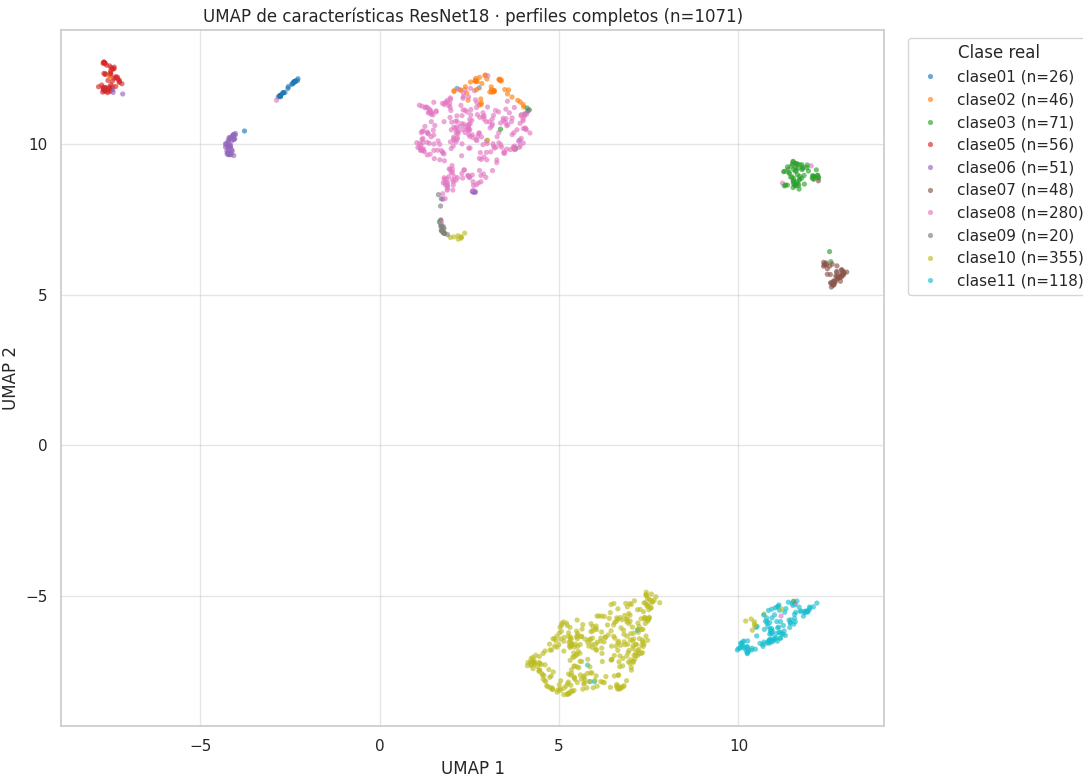

In [7]:
clases = sorted(tabla_umap["clase_carpeta"].unique())
recuentos = tabla_umap["clase_carpeta"].value_counts()
paleta = dict(
    zip(
        clases,
        sns.color_palette(
            "tab10" if len(clases) <= 10 else "tab20", n_colors=len(clases)
        ),
    )
)

with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
    figura_umap, eje_umap = plt.subplots(figsize=(11, 8))
    sns.scatterplot(
        data=tabla_umap,
        x="UMAP_1",
        y="UMAP_2",
        hue="clase_carpeta",
        hue_order=clases,
        palette=paleta,
        s=14,
        alpha=0.65,
        linewidth=0,
        ax=eje_umap,
    )
    eje_umap.set(
        title=f"UMAP de características ResNet18 · perfiles completos (n={len(tabla_umap)})",
        xlabel="UMAP 1",
        ylabel="UMAP 2",
    )
    handles, labels = eje_umap.get_legend_handles_labels()
    eje_umap.legend(
        handles,
        [f"{clase} (n={recuentos[clase]})" for clase in labels],
        title="Clase real",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    figura_umap.tight_layout()

display(figura_umap)
plt.close(figura_umap)

## Exportación

El CSV conserva las filas de las clases incluidas (`clase04` y `sin_clase` quedan excluidas), con todas sus columnas originales, sus valores faltantes y su orden; agrega las rutas, las carpetas y las coordenadas `UMAP_1` y `UMAP_2`. El PNG guarda la misma figura mostrada. Ambos archivos llevan el prefijo `umap_perfiles_completos_` en `../../output/umap`.

In [8]:
pd.testing.assert_frame_equal(
    tabla_umap[list(metadata_completos.columns)],
    metadata_completos.reset_index(drop=True),
)
rutas_guardadas = guardar_resultado_umap(
    tabla=tabla_umap,
    figura=figura_umap,
    ruta_csv=CSV_PATH,
    ruta_figura=FIGURE_PATH,
)
display(
    tabla_umap[
        ["Identificador", "ruta_relativa", "clase_carpeta", "UMAP_1", "UMAP_2"]
    ].head(10)
)
for ruta in rutas_guardadas:
    print(f"Archivo generado: {ruta_relativa(ruta)}")

,Identificador,ruta_relativa,clase_carpeta,UMAP_1,UMAP_2
0,al_03a,clase11/al_03a.png,clase11,10.166957,-6.685034
1,al_03b,clase11/al_03b.png,clase11,10.881978,-6.426226
2,al_03c,clase11/al_03c.png,clase11,11.286960,-5.523441
3,al_03d,clase11/al_03d.png,clase11,5.987044,-7.825027
4,al_03e,clase11/al_03e.png,clase11,10.157465,-6.721118
5,al_03f,clase11/al_03f.png,clase11,11.627347,-5.152459
6,al_03g,clase11/al_03g.png,clase11,11.171822,-5.836324
7,al_03h,clase11/al_03h.png,clase11,11.408569,-5.782718
8,al_03i,clase11/al_03i.png,clase11,10.055464,-6.553684
9,al_03j,clase11/al_03j.png,clase11,10.709464,-6.510375


Archivo generado: output\umap\umap_perfiles_completos_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv
Archivo generado: output\umap\umap_perfiles_completos_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
